<a href="https://colab.research.google.com/github/Fata-Haidar/PCVK_Ganjil_2026/blob/main/pertemuan_10/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama : Fata Haidar Aly

NIM : 244107020108

Kelas : TI-3C

Absen: 07

Link github : https://github.com/Fata-Haidar/PCVK_Ganjil_2026/tree/main/pertemuan_10

Link colab :https://colab.research.google.com/drive/1CNxSN7a1_u39GKGsFgN0-2OM6Bc7n5Rh?usp=sharing

# Week 10 — Dasar-Dasar Deteksi Objek
**Mata kuliah:** Pengolahan Citra dan Visi Komputer  
**Praktikum:** D1 Object Detection, D2 Feature Matching dan Face Detection, serta D3 pengayaan CNN.

Notebook ini disusun mengikuti urutan nomor pada Modul 10. Jalankan sel dari atas ke bawah di Google Colab.

## Persiapan berkas
1. Simpan/copy folder gambar dari tautan Google Drive yang tercantum pada modul ke Google Drive pribadi.
2. Pastikan folder gambar dapat diakses dari Google Colab.
3. Sesuaikan variabel `BASE_DIR` pada nomor 1 dengan lokasi folder gambar Anda.
4. Nomor 14 dan D3 membutuhkan foto KTM serta dataset karakter milik sendiri. Jangan membagikan foto KTM yang memuat NIM, QR, atau data pribadi ke ruang publik.
5. Nomor 12 membutuhkan izin akses kamera dari browser.

**Catatan:** Notebook ini menyediakan implementasi dan visualisasi. Hasil aktual baru muncul setelah seluruh gambar/dataset tersedia dan sel dijalankan di Colab.

## 1. Membuat notebook dan mengimpor library

Buat notebook baru di Google Colab dengan nama **Week10.ipynb**. Hubungkan Google Drive, lalu sesuaikan `BASE_DIR` dengan folder `Images` dari bahan praktikum.

In [3]:
# Import library
import os
import time
import base64
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from google.colab import drive
drive.mount('/content/drive')

# GANTI lokasi ini sesuai folder Images pada Google Drive Anda.
# Contoh struktur: MyDrive/PCVK/Images/facedet/...
BASE_DIR = Path('/content/drive/MyDrive/PCVK/')

if not BASE_DIR.exists():
    print(f'Folder belum ditemukan: {BASE_DIR}')
    print('Ubah BASE_DIR ke lokasi folder Images Anda, lalu jalankan ulang sel ini.')

def cari_file(nama, alternatif=(), subdir=None):
    """Mencari file berdasarkan nama persis di folder bahan praktikum."""
    nama_dicari = [nama, *alternatif]
    root = BASE_DIR / subdir if subdir else BASE_DIR
    if not root.exists():
        root = BASE_DIR
    daftar = [p for p in root.rglob('*') if p.is_file()]
    for target in nama_dicari:
        for p in daftar:
            if p.name.lower() == str(target).lower():
                return p
    raise FileNotFoundError(
        f"File tidak ditemukan: {nama_dicari}. Periksa BASE_DIR={BASE_DIR} "
        "dan nama file pada folder bahan praktikum."
    )

def baca_warna(nama, alternatif=(), subdir=None):
    path = cari_file(nama, alternatif, subdir)
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f'Gagal membaca gambar: {path}')
    return img, path

def tampilkan_bgr(img, judul='Gambar', figsize=(8, 6)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(judul)
    plt.axis('off')
    plt.show()

print('OpenCV:', cv2.__version__)
print('Folder gambar:', BASE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OpenCV: 4.14.0
Folder gambar: /content/drive/MyDrive/PCVK


## D1. Praktikum Deteksi Obyek Dasar

## 2. Template Matching — enam metode OpenCV

Gambar masukan: `cats_and_bunnies.jpg`. Template: `cat2_templatejpg.jpg` (beberapa salinan bahan dapat memakai nama `cat2_template.jpg`). Enam metode yang diuji adalah `TM_SQDIFF`, `TM_SQDIFF_NORMED`, `TM_CCORR`, `TM_CCORR_NORMED`, `TM_CCOEFF`, dan `TM_CCOEFF_NORMED`.

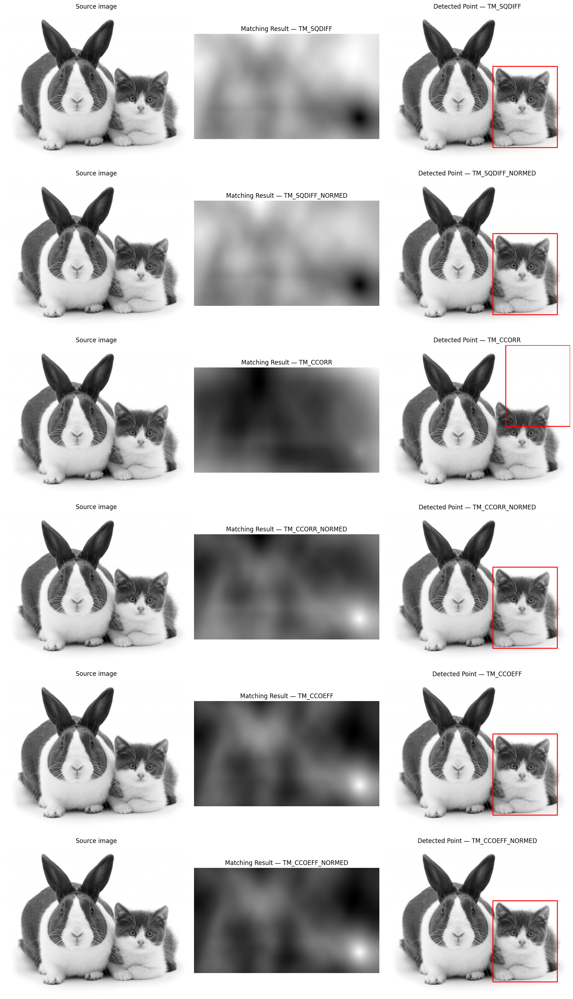

In [4]:
source_path = cari_file('cats_and_bunnies.jpg')
template_path = cari_file(
    'cat2_templatejpg.jpg',
    alternatif=('cat2_template.jpg', 'cat2_templatejpg.jpeg')
)

source = cv2.imread(str(source_path), cv2.IMREAD_GRAYSCALE)
template = cv2.imread(str(template_path), cv2.IMREAD_GRAYSCALE)

if source is None or template is None:
    raise ValueError('Gambar source/template tidak dapat dibaca.')

h, w = template.shape
if h > source.shape[0] or w > source.shape[1]:
    raise ValueError('Ukuran template harus lebih kecil daripada gambar masukan.')

methods = [
    ('TM_SQDIFF', cv2.TM_SQDIFF),
    ('TM_SQDIFF_NORMED', cv2.TM_SQDIFF_NORMED),
    ('TM_CCORR', cv2.TM_CCORR),
    ('TM_CCORR_NORMED', cv2.TM_CCORR_NORMED),
    ('TM_CCOEFF', cv2.TM_CCOEFF),
    ('TM_CCOEFF_NORMED', cv2.TM_CCOEFF_NORMED),
]

fig, axes = plt.subplots(len(methods), 3, figsize=(16, 28))
for row, (nama_metode, metode) in enumerate(methods):
    hasil = cv2.matchTemplate(source, template, metode)
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(hasil)

    # SQDIFF memilih nilai minimum; metode lainnya memilih nilai maksimum.
    lokasi = min_loc if metode in (cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED) else max_loc
    x, y = lokasi
    deteksi = cv2.cvtColor(source, cv2.COLOR_GRAY2BGR)
    cv2.rectangle(deteksi, (x, y), (x + w, y + h), (0, 0, 255), 3)

    axes[row, 0].imshow(source, cmap='gray')
    axes[row, 0].set_title('Source image')
    axes[row, 1].imshow(hasil, cmap='gray')
    axes[row, 1].set_title(f'Matching Result — {nama_metode}')
    axes[row, 2].imshow(cv2.cvtColor(deteksi, cv2.COLOR_BGR2RGB))
    axes[row, 2].set_title(f'Detected Point — {nama_metode}')
    for ax in axes[row]:
        ax.axis('off')

plt.tight_layout()
plt.show()

## 3. Template Matching manual untuk multiple object — tanpa OpenCV

Gambar masukan: `bahrain.jpg`; template: `bahrain-template.jpg`. Bagian pencocokan berikut tidak memakai fungsi matching OpenCV. Perhitungan menggunakan NumPy dan korelasi FFT SciPy untuk menghitung *zero-mean normalized cross-correlation* (ZNCC), kemudian mengambil beberapa puncak skor yang terpisah.

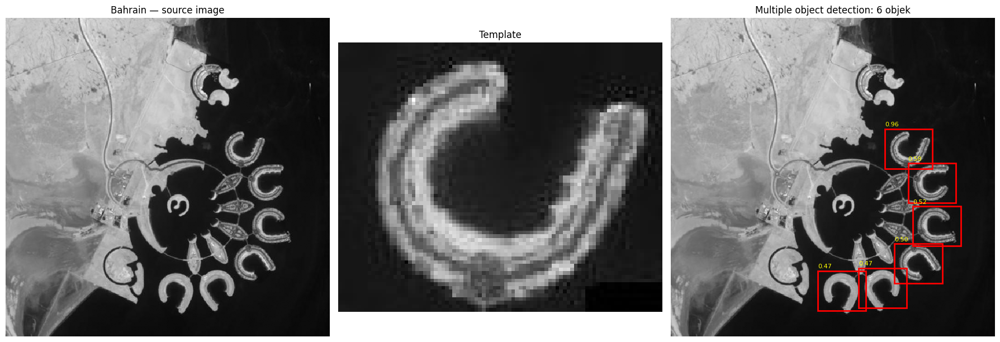

Jumlah lokasi terdeteksi: 6


In [4]:
from scipy.signal import fftconvolve
from scipy.ndimage import maximum_filter

bahrain_path = cari_file('bahrain.jpg')
bahrain_template_path = cari_file(
    'bahrain-template.jpg',
    alternatif=('bahrain_template.jpg',)
)

# Baca menggunakan PIL, bukan OpenCV.
img_pil = Image.open(bahrain_path).convert('L')
tpl_pil = Image.open(bahrain_template_path).convert('L')
img_np = np.asarray(img_pil, dtype=np.float32)
tpl_np = np.asarray(tpl_pil, dtype=np.float32)

def integral_image(arr):
    return np.pad(arr.cumsum(axis=0).cumsum(axis=1), ((1, 0), (1, 0)))

def jumlah_patch(ii, tinggi, lebar):
    return (ii[tinggi:, lebar:] - ii[:-tinggi, lebar:]
            - ii[tinggi:, :-lebar] + ii[:-tinggi, :-lebar])

def zncc_manual(gambar, template):
    """Menghitung ZNCC seluruh posisi template tanpa cv2.matchTemplate."""
    th, tw = template.shape
    if th > gambar.shape[0] or tw > gambar.shape[1]:
        raise ValueError('Template lebih besar daripada gambar sumber.')

    template_zero = template - template.mean()
    energi_template = np.sum(template_zero ** 2)
    if energi_template <= 1e-10:
        raise ValueError('Template hampir konstan; ZNCC tidak dapat dihitung.')

    # Korelasi silang dihitung melalui FFT.
    pembilang = fftconvolve(gambar, template_zero[::-1, ::-1], mode='valid')

    ii = integral_image(gambar)
    ii2 = integral_image(gambar ** 2)
    n = th * tw
    sum_patch = jumlah_patch(ii, th, tw)
    sum2_patch = jumlah_patch(ii2, th, tw)
    variansi_patch = np.maximum(sum2_patch - (sum_patch ** 2) / n, 1e-10)

    skor = pembilang / np.sqrt(variansi_patch * energi_template)
    return np.clip(skor, -1.0, 1.0)

def iou_box(a, b):
    ax, ay, aw, ah = a
    bx, by, bw, bh = b
    x1, y1 = max(ax, bx), max(ay, by)
    x2, y2 = min(ax + aw, bx + bw), min(ay + ah, by + bh)
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = aw * ah + bw * bh - inter
    return inter / union if union else 0.0

def ambil_puncak(skor, tinggi, lebar, threshold=0.45, maksimum=30):
    lokal = maximum_filter(skor, size=(tinggi, lebar), mode='constant')
    ys, xs = np.where((skor >= threshold) & (skor >= lokal - 1e-7))
    kandidat = sorted(
        [(int(x), int(y), float(skor[y, x])) for y, x in zip(ys, xs)],
        key=lambda z: z[2], reverse=True
    )
    terpilih = []
    for x, y, nilai in kandidat:
        kotak = (x, y, lebar, tinggi)
        if all(iou_box(kotak, k[:4]) < 0.25 for k in terpilih):
            terpilih.append((x, y, lebar, tinggi, nilai))
        if len(terpilih) >= maksimum:
            break
    return terpilih

skor = zncc_manual(img_np, tpl_np)
th, tw = tpl_np.shape
# Jika deteksi terlalu sedikit/banyak, ubah threshold antara 0.30–0.80.
THRESHOLD_ZNCC = 0.45
kotak_ditemukan = ambil_puncak(skor, th, tw, threshold=THRESHOLD_ZNCC)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(img_np, cmap='gray')
axes[0].set_title('Bahrain — source image')
axes[1].imshow(tpl_np, cmap='gray')
axes[1].set_title('Template')
axes[2].imshow(img_np, cmap='gray')
axes[2].set_title(f'Multiple object detection: {len(kotak_ditemukan)} objek')
for x, y, ww, hh, nilai in kotak_ditemukan:
    axes[2].add_patch(plt.Rectangle((x, y), ww, hh, fill=False, edgecolor='red', linewidth=2))
    axes[2].text(x, max(0, y-5), f'{nilai:.2f}', color='yellow', fontsize=8)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Jumlah lokasi terdeteksi:', len(kotak_ditemukan))

## 4. Edge Detection — Sobel, Canny, dan Laplacian

Gambar yang digunakan: `car-park.jpg`. Sobel menghitung gradien arah X dan Y, Canny melakukan tahapan penghalusan dan penentuan tepi, sedangkan Laplacian menghitung turunan kedua setelah Gaussian Blur.

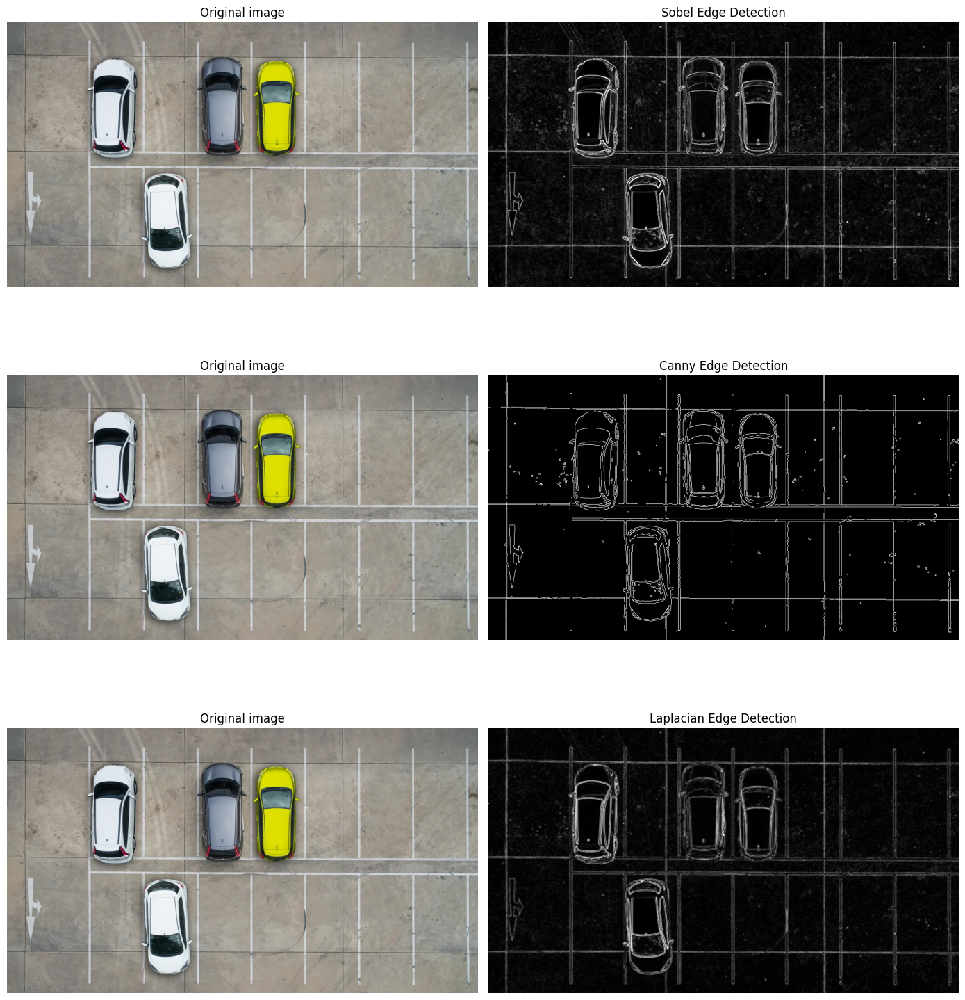

In [5]:
car_park, car_park_path = baca_warna('car-park.jpg')
gray_car = cv2.cvtColor(car_park, cv2.COLOR_BGR2GRAY)

# Sobel
sobel_x = cv2.Sobel(gray_car, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_car, cv2.CV_64F, 0, 1, ksize=3)
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)
sobel_combined = cv2.addWeighted(sobel_x_abs, 0.5, sobel_y_abs, 0.5, 0)

# Canny
canny_edges = cv2.Canny(gray_car, 100, 200)

# Laplacian: haluskan terlebih dahulu untuk mengurangi noise.
blur_car = cv2.GaussianBlur(gray_car, (3, 3), 0)
laplacian = cv2.Laplacian(blur_car, cv2.CV_64F, ksize=3)
laplacian_abs = cv2.convertScaleAbs(laplacian)

fig, axes = plt.subplots(3, 2, figsize=(14, 16))
items = [
    (car_park, 'Original image', True),
    (sobel_combined, 'Sobel Edge Detection', False),
    (car_park, 'Original image', True),
    (canny_edges, 'Canny Edge Detection', False),
    (car_park, 'Original image', True),
    (laplacian_abs, 'Laplacian Edge Detection', False),
]
for ax, (im, title, is_color) in zip(axes.flat, items):
    if is_color:
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(im, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Corner Detection — Harris dan Shi-Tomasi

Gambar yang digunakan: `chess-board.jpg`. Harris menggunakan respons sudut berdasarkan matriks momen; Shi-Tomasi memilih sudut berdasarkan nilai eigen minimum melalui `goodFeaturesToTrack()`.

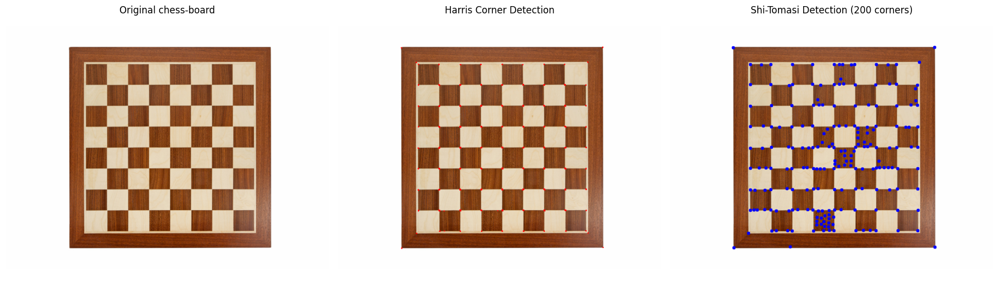

In [6]:
chess, chess_path = baca_warna('chess-board.jpg')
gray_chess = cv2.cvtColor(chess, cv2.COLOR_BGR2GRAY)

# Harris Corner Detection
gray_float = np.float32(gray_chess)
harris_response = cv2.cornerHarris(gray_float, blockSize=2, ksize=3, k=0.04)
harris_dilated = cv2.dilate(harris_response, None)
harris_result = chess.copy()
harris_result[harris_dilated > 0.01 * harris_dilated.max()] = [0, 0, 255]

# Shi-Tomasi Corner Detection
shi_result = chess.copy()
corners = cv2.goodFeaturesToTrack(
    gray_chess, maxCorners=200, qualityLevel=0.01, minDistance=10
)
jumlah_sudut = 0
if corners is not None:
    corners = np.int32(corners)
    jumlah_sudut = len(corners)
    for corner in corners:
        x, y = corner.ravel()
        cv2.circle(shi_result, (int(x), int(y)), 5, (255, 0, 0), -1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(chess, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original chess-board')
axes[1].imshow(cv2.cvtColor(harris_result, cv2.COLOR_BGR2RGB))
axes[1].set_title('Harris Corner Detection')
axes[2].imshow(cv2.cvtColor(shi_result, cv2.COLOR_BGR2RGB))
axes[2].set_title(f'Shi-Tomasi Detection ({jumlah_sudut} corners)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Grid Detection — Hough Transform

Gambar yang digunakan: `sudoku.jpg`. Tahapan mengikuti modul: Canny, dilasi, erosi, Hough Transform, lalu penggabungan garis yang berdekatan agar garis yang sama tidak digambar berulang kali.

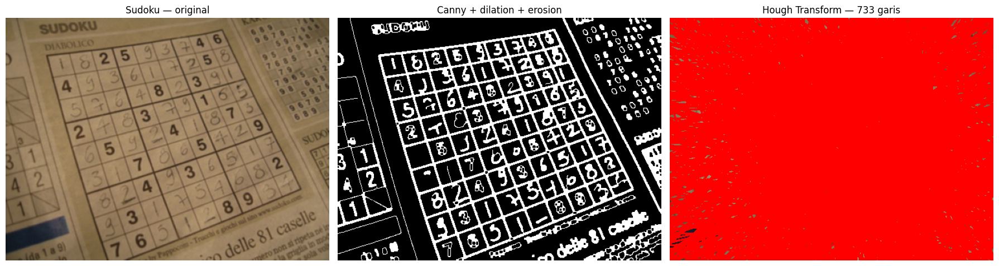

In [7]:
sudoku, sudoku_path = baca_warna('sudoku.jpg')
gray_sudoku = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)

edges_sudoku = cv2.Canny(gray_sudoku, 50, 150)
kernel_grid = np.ones((3, 3), np.uint8)
dilated_sudoku = cv2.dilate(edges_sudoku, kernel_grid, iterations=1)
processed_sudoku = cv2.erode(dilated_sudoku, kernel_grid, iterations=1)

lines_raw = cv2.HoughLines(processed_sudoku, 1, np.pi / 180, threshold=120)

def gabungkan_garis_hough(lines, rho_tol=15, theta_tol=np.deg2rad(2.0)):
    """Mengelompokkan garis Hough yang parameter rho/theta-nya berdekatan."""
    if lines is None:
        return []
    kelompok = []
    for item in lines[:, 0, :]:
        rho, theta = float(item[0]), float(item[1])
        cocok = None
        for g in kelompok:
            if abs(rho - g[0]) <= rho_tol and abs(theta - g[1]) <= theta_tol:
                cocok = g
                break
        if cocok is None:
            kelompok.append([rho, theta, 1])
        else:
            n = cocok[2]
            cocok[0] = (cocok[0] * n + rho) / (n + 1)
            cocok[1] = (cocok[1] * n + theta) / (n + 1)
            cocok[2] = n + 1
    return [(g[0], g[1]) for g in kelompok]

garis = gabungkan_garis_hough(lines_raw)
hough_result = sudoku.copy()
panjang = max(sudoku.shape[:2]) * 2
for rho, theta in garis:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 + panjang * (-b)), int(y0 + panjang * a))
    p2 = (int(x0 - panjang * (-b)), int(y0 - panjang * a))
    cv2.line(hough_result, p1, p2, (0, 0, 255), 2)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(sudoku, cv2.COLOR_BGR2RGB))
axes[0].set_title('Sudoku — original')
axes[1].imshow(processed_sudoku, cmap='gray')
axes[1].set_title('Canny + dilation + erosion')
axes[2].imshow(cv2.cvtColor(hough_result, cv2.COLOR_BGR2RGB))
axes[2].set_title(f'Hough Transform — {len(garis)} garis')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 7. Contour Detection — `findContours()`

Gambar yang digunakan: `laptop.jpg`. Citra diubah menjadi grayscale, dihaluskan, lalu dibuat tepinya. Kontur luar diambil dengan `RETR_EXTERNAL` dan digambar pada citra asli menggunakan `drawContours()`.

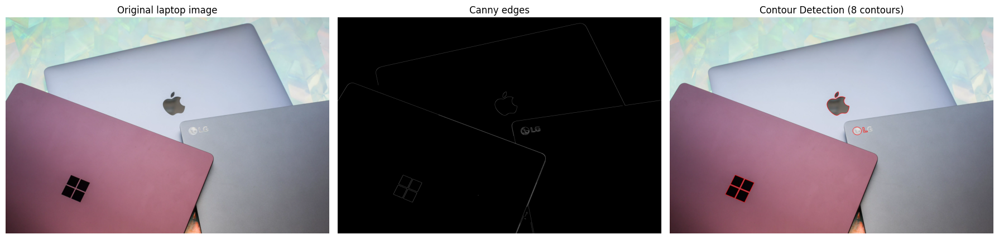

In [8]:
laptop, laptop_path = baca_warna('laptop.jpg')
gray_laptop = cv2.cvtColor(laptop, cv2.COLOR_BGR2GRAY)
blur_laptop = cv2.GaussianBlur(gray_laptop, (5, 5), 0)
edges_laptop = cv2.Canny(blur_laptop, 50, 150)

contours, hierarchy = cv2.findContours(
    edges_laptop.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
contour_result = laptop.copy()
contours_besar = [c for c in contours if cv2.contourArea(c) > 500]
cv2.drawContours(contour_result, contours_besar, -1, (0, 0, 255), 3)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(laptop, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original laptop image')
axes[1].imshow(edges_laptop, cmap='gray')
axes[1].set_title('Canny edges')
axes[2].imshow(cv2.cvtColor(contour_result, cv2.COLOR_BGR2RGB))
axes[2].set_title(f'Contour Detection ({len(contours_besar)} contours)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## D2. Praktikum Feature Matching dan Face Detection

## 8. Face Detection pada gambar lain dalam folder `facedet`

Menggunakan Haar Cascade `haarcascade_frontalface_alt.xml` dari OpenCV. Program memproses seluruh gambar di dalam folder `facedet` dan menggambar kotak pada wajah yang terdeteksi.

Copy of KTM lama.jpg: 1 wajah terdeteksi


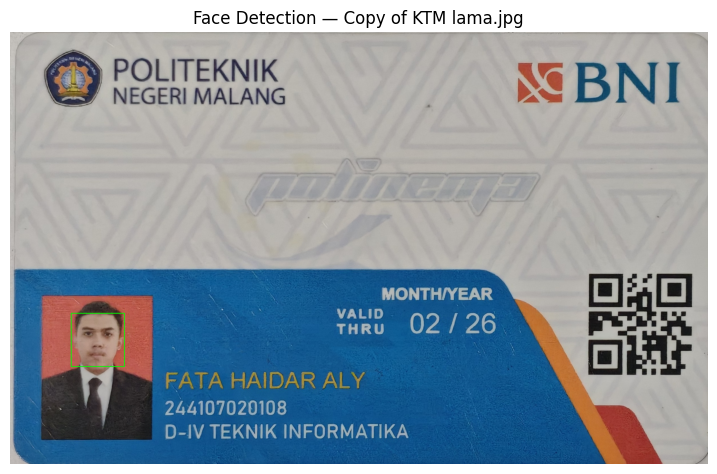

cat.png: 0 wajah terdeteksi


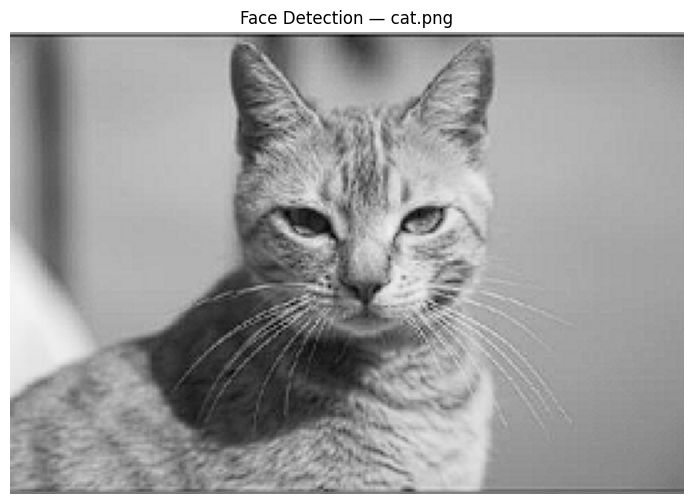

kartini.jpg: 1 wajah terdeteksi


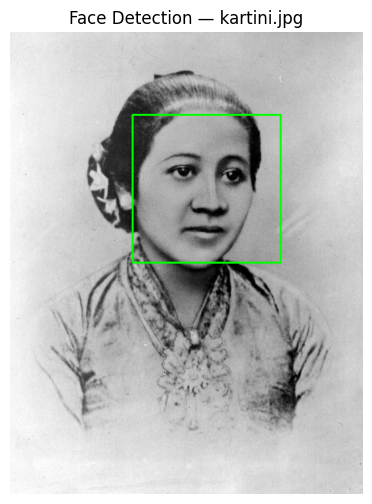

mask.png: 5 wajah terdeteksi


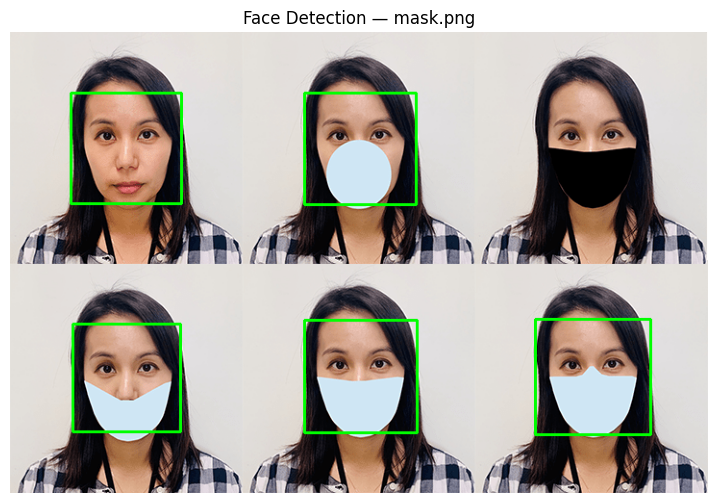

mjordan.jpg: 1 wajah terdeteksi


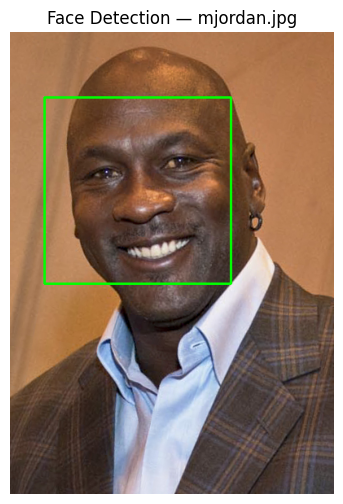

people.png: 9 wajah terdeteksi


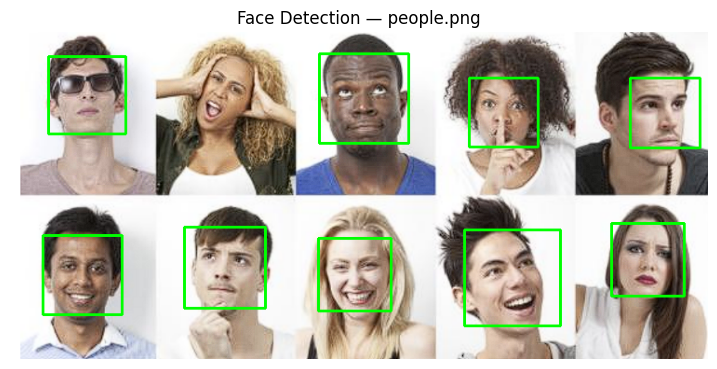

prabowo.jpg: 1 wajah terdeteksi


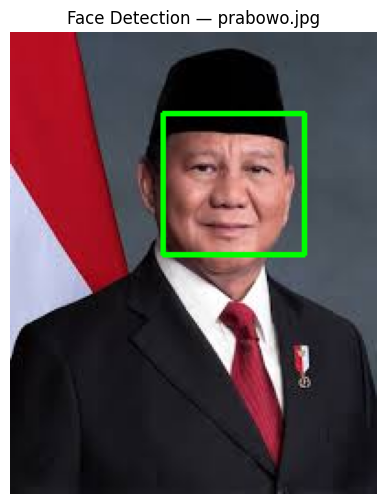

solvayconf.jpg: 27 wajah terdeteksi


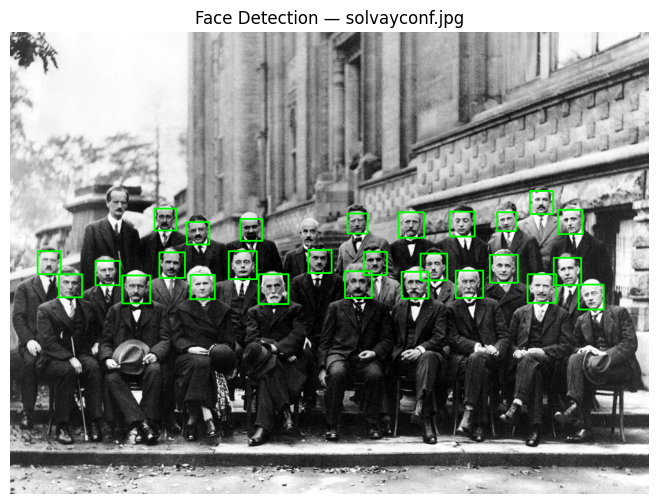

In [5]:
face_xml = cv2.data.haarcascades + 'haarcascade_frontalface_alt.xml'
face_cascade = cv2.CascadeClassifier(face_xml)
if face_cascade.empty():
    raise RuntimeError('Haar Cascade wajah tidak berhasil dimuat.')

# Khusus nomor 8: hanya baca gambar dari MyDrive/PCVK/facedet.
FACE_DIR = BASE_DIR / 'facedet'
if not FACE_DIR.exists():
    raise FileNotFoundError(
        f'Folder facedet tidak ditemukan: {FACE_DIR}. '
        'Buat folder facedet di dalam MyDrive/PCVK dan masukkan gambar untuk face detection.'
    )

ekstensi_gambar = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
daftar_facedet = sorted(
    p for p in FACE_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in ekstensi_gambar
)

if not daftar_facedet:
    print('Tidak ada gambar pada folder facedet.')
else:
    for path in daftar_facedet:
        frame = cv2.imread(str(path))
        if frame is None:
            continue
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(
            gray, scaleFactor=1.1, minNeighbors=5, minSize=(20, 20)
        )
        output = frame.copy()
        for (x, y, w, h) in faces:
            cv2.rectangle(output, (x, y), (x+w, y+h), (0, 255, 0), 2)
        print(f'{path.name}: {len(faces)} wajah terdeteksi')
        tampilkan_bgr(output, f'Face Detection — {path.name}', figsize=(9, 6))

## 9. Face Detection khusus wajah kucing

Modul meminta pendeteksian wajah kucing menggunakan pretrained feature. Jika XML belum tersedia secara lokal, sel berikut mengunduh Haar Cascade wajah kucing dari repositori resmi OpenCV.

Wajah kucing terdeteksi: 1


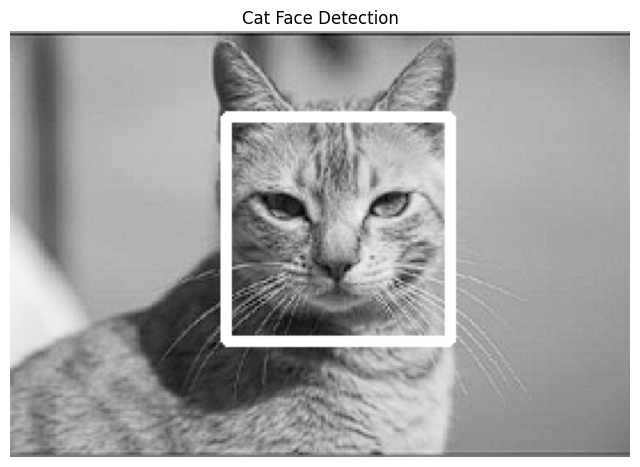

In [6]:
cat_xml_path = Path('/content/haarcascade_frontalcatface.xml')
cat_xml_url = (
    'https://raw.githubusercontent.com/opencv/opencv/master/'
    'data/haarcascades/haarcascade_frontalcatface.xml'
)
if not cat_xml_path.exists():
    urllib.request.urlretrieve(cat_xml_url, cat_xml_path)

cat_cascade = cv2.CascadeClassifier(str(cat_xml_path))
if cat_cascade.empty():
    raise RuntimeError('Cascade wajah kucing gagal dimuat. Periksa koneksi atau file XML.')

# Cari gambar kucing dalam folder facedet. Jika nama file berbeda, ganti CAT_IMAGE_PATH.
kandidat_kucing = [
    p for p in daftar_facedet
    if 'cat' in p.stem.lower() or 'kucing' in p.stem.lower()
]
if kandidat_kucing:
    CAT_IMAGE_PATH = kandidat_kucing[0]
else:
    CAT_IMAGE_PATH = None
    print('Nama file kucing tidak dikenali otomatis. Atur CAT_IMAGE_PATH secara manual.')

if CAT_IMAGE_PATH is not None:
    cat_img = cv2.imread(str(CAT_IMAGE_PATH))
    cat_gray = cv2.cvtColor(cat_img, cv2.COLOR_BGR2GRAY)
    cat_faces = cat_cascade.detectMultiScale(
        cat_gray, scaleFactor=1.05, minNeighbors=3, minSize=(35, 35)
    )
    cat_output = cat_img.copy()
    for (x, y, w, h) in cat_faces:
        cv2.rectangle(cat_output, (x, y), (x+w, y+h), (255, 255, 255), 3)
    print('Wajah kucing terdeteksi:', len(cat_faces))
    tampilkan_bgr(cat_output, 'Cat Face Detection')

## 10. Eyes Detection pada wajah Pak Prabowo

Menggunakan Haar Cascade mata. Gambar `prabowo.jpg` dicari pada folder bahan praktikum. Jika nama/path berbeda, sesuaikan variabel `PRABOWO_IMAGE_PATH`.

Jumlah wajah: 1
Jumlah mata: 2


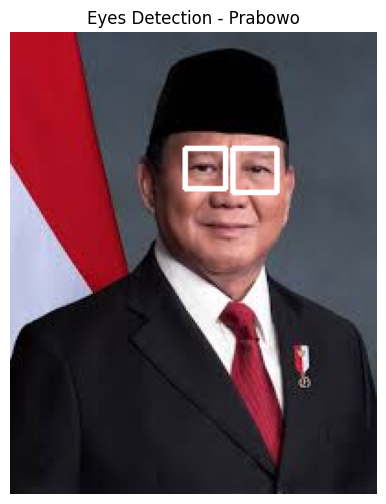

In [8]:
PRABOWO_IMAGE_PATH = cari_file(
    'prabowo.jpg',
    alternatif=('prabowo.jpeg', 'prabowo.png'),
    subdir='facedet'
)

prabowo_img = cv2.imread(str(PRABOWO_IMAGE_PATH))
prabowo_gray = cv2.cvtColor(prabowo_img, cv2.COLOR_BGR2GRAY)

# Deteksi wajah
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_alt.xml'
)

# Deteksi mata
eye_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_eye.xml'
)

faces = face_cascade.detectMultiScale(
    prabowo_gray,
    scaleFactor=1.1,
    minNeighbors=4,
    minSize=(30, 30)
)

eye_result = prabowo_img.copy()
jumlah_mata = 0

for (x, y, w, h) in faces:

    # Area wajah
    face_roi = prabowo_gray[y:y+h, x:x+w]

    # Fokus pada bagian atas wajah
    eye_roi = face_roi[0:int(h * 0.65), :]

    eyes = eye_cascade.detectMultiScale(
        eye_roi,
        scaleFactor=1.03,
        minNeighbors=4,
        minSize=(8, 8),
        maxSize=(40, 40)
    )

    for (ex, ey, ew, eh) in eyes:
        cv2.rectangle(
            eye_result,
            (x+ex, y+ey),
            (x+ex+ew, y+ey+eh),
            (255, 255, 255),
            2
        )

        jumlah_mata += 1

print('Jumlah wajah:', len(faces))
print('Jumlah mata:', jumlah_mata)

tampilkan_bgr(
    eye_result,
    'Eyes Detection - Prabowo'
)

## 11. Smile Detection pada gambar `people`

Wajah dideteksi terlebih dahulu. Selanjutnya Haar Cascade senyuman dijalankan pada setiap area wajah (ROI), sehingga pencarian senyum lebih terarah.

Wajah: 9 | kandidat senyuman: 1


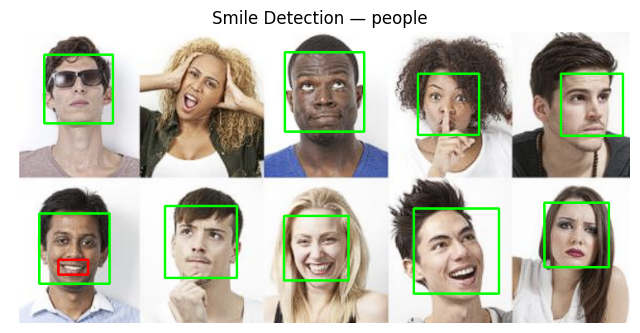

In [9]:
PEOPLE_IMAGE_PATH = cari_file(
    'people.jpg',
    alternatif=('people.jpeg', 'people.png', 'people.JPG'),
    subdir='facedet'
)
people_img = cv2.imread(str(PEOPLE_IMAGE_PATH))
people_gray = cv2.cvtColor(people_img, cv2.COLOR_BGR2GRAY)

smile_xml = cv2.data.haarcascades + 'haarcascade_smile.xml'
smile_cascade = cv2.CascadeClassifier(smile_xml)
if smile_cascade.empty():
    raise RuntimeError('Cascade senyuman gagal dimuat.')

people_faces = face_cascade.detectMultiScale(
    people_gray, scaleFactor=1.1, minNeighbors=4, minSize=(25, 25)
)
smile_result = people_img.copy()
jumlah_senyum = 0

for (x, y, w, h) in people_faces:
    cv2.rectangle(smile_result, (x, y), (x+w, y+h), (0, 255, 0), 2)
    roi_gray = people_gray[y:y+h, x:x+w]
    roi_color = smile_result[y:y+h, x:x+w]
    smiles = smile_cascade.detectMultiScale(
        roi_gray, scaleFactor=1.7, minNeighbors=20, minSize=(15, 15)
    )
    for (sx, sy, sw, sh) in smiles:
        cv2.rectangle(roi_color, (sx, sy), (sx+sw, sy+sh), (0, 0, 255), 2)
        jumlah_senyum += 1

print('Wajah:', len(people_faces), '| kandidat senyuman:', jumlah_senyum)
tampilkan_bgr(smile_result, 'Smile Detection — people')

## 12. Face Tracking menggunakan kamera Google Colab

Google Colab tidak dapat memakai `cv2.VideoCapture(0)` secara langsung untuk kamera lokal. Kode berikut meminta izin kamera browser, mengambil frame berkala melalui JavaScript, lalu mendeteksi wajah pada setiap frame. Tekan tombol stop/interrupt pada Colab jika ingin menghentikan lebih awal.

<IPython.core.display.Javascript object>

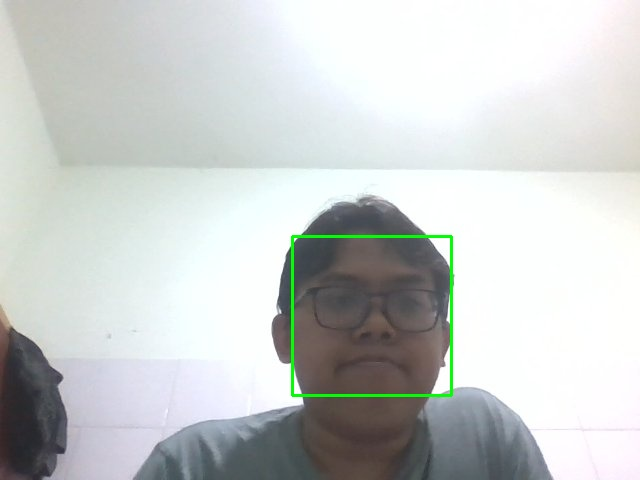

Face tracking — frame 1/40 | wajah: 1
Face tracking — frame 2/40 | wajah: 0
Face tracking — frame 3/40 | wajah: 1
Face tracking — frame 4/40 | wajah: 0
Face tracking — frame 5/40 | wajah: 1
Face tracking — frame 6/40 | wajah: 1
Face tracking — frame 7/40 | wajah: 1
Face tracking — frame 8/40 | wajah: 1
Face tracking — frame 9/40 | wajah: 1
Face tracking — frame 10/40 | wajah: 1
Face tracking — frame 11/40 | wajah: 1
Face tracking — frame 12/40 | wajah: 1
Face tracking — frame 13/40 | wajah: 1
Face tracking — frame 14/40 | wajah: 0
Face tracking — frame 15/40 | wajah: 0
Face tracking — frame 16/40 | wajah: 0
Face tracking — frame 17/40 | wajah: 0
Face tracking — frame 18/40 | wajah: 0
Face tracking — frame 19/40 | wajah: 0
Face tracking — frame 20/40 | wajah: 0
Face tracking — frame 21/40 | wajah: 1
Face tracking — frame 22/40 | wajah: 0
Face tracking — frame 23/40 | wajah: 1
Face tracking — frame 24/40 | wajah: 1
Face tracking — frame 25/40 | wajah: 1
Face tracking — frame 26/40 | waja

In [14]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from IPython.display import Image as IPyImage
import base64
import time
import cv2
import numpy as np

# Pastikan Haar Cascade wajah tersedia.
face_xml = cv2.data.haarcascades + 'haarcascade_frontalface_alt.xml'
face_cascade = cv2.CascadeClassifier(face_xml)
if face_cascade.empty():
    raise RuntimeError('Haar Cascade wajah tidak berhasil dimuat.')

# Fungsi kamera ditempelkan ke window agar selalu bisa dipanggil oleh eval_js.
display(Javascript(r"""
window.__pcvkVideo = null;
window.__pcvkStream = null;

window.__pcvkStart = async function() {
  if (window.__pcvkVideo && window.__pcvkStream) return true;

  const box = document.createElement('div');
  box.id = 'pcvk-camera-box';
  box.style.margin = '10px 0';

  const video = document.createElement('video');
  video.setAttribute('playsinline', '');
  video.autoplay = true;
  video.muted = true;
  video.style.width = '480px';
  video.style.maxWidth = '100%';
  video.style.border = '2px solid #777';
  box.appendChild(video);
  document.body.appendChild(box);

  const stream = await navigator.mediaDevices.getUserMedia({
    video: true,
    audio: false
  });
  video.srcObject = stream;
  await video.play();

  if (video.videoWidth === 0) {
    await new Promise(resolve => {
      video.onloadedmetadata = resolve;
    });
  }

  window.__pcvkVideo = video;
  window.__pcvkStream = stream;
  return true;
};

window.__pcvkCapture = function() {
  const video = window.__pcvkVideo;
  if (!video || !window.__pcvkStream) {
    throw new Error('Kamera belum aktif. Jalankan __pcvkStart terlebih dahulu.');
  }

  const canvas = document.createElement('canvas');
  canvas.width = video.videoWidth;
  canvas.height = video.videoHeight;
  canvas.getContext('2d').drawImage(video, 0, 0);
  return canvas.toDataURL('image/jpeg', 0.85);
};

window.__pcvkStop = function() {
  if (window.__pcvkStream) {
    window.__pcvkStream.getTracks().forEach(track => track.stop());
  }
  const box = document.getElementById('pcvk-camera-box');
  if (box) box.remove();

  window.__pcvkVideo = null;
  window.__pcvkStream = null;
  return true;
};
"""))

# Minta izin kamera browser.
eval_js('window.__pcvkStart()')

MAKS_FRAME = 40  # jumlah frame yang diproses
display_handle = None

try:
    for nomor_frame in range(MAKS_FRAME):
        # Ambil frame dari fungsi global di browser.
        data_url = eval_js('window.__pcvkCapture()')
        data_bytes = base64.b64decode(data_url.split(',')[1])
        frame_array = np.frombuffer(data_bytes, dtype=np.uint8)
        frame = cv2.imdecode(frame_array, cv2.IMREAD_COLOR)

        if frame is None:
            print('Frame kamera gagal dibaca.')
            continue

        gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces_frame = face_cascade.detectMultiScale(
            gray_frame,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(30, 30)
        )

        for (x, y, w, h) in faces_frame:
            cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image_output = IPyImage(data=cv2.imencode('.jpg', frame)[1].tobytes())

        if display_handle is None:
            display_handle = display(image_output, display_id=True)
        else:
            display_handle.update(image_output)

        print(f'Face tracking — frame {nomor_frame + 1}/{MAKS_FRAME} | wajah: {len(faces_frame)}')
        time.sleep(0.08)

finally:
    # Hentikan kamera dengan aman, termasuk jika proses dihentikan/error.
    try:
        eval_js('window.__pcvkStop && window.__pcvkStop()')
    except Exception:
        print('Jika kamera masih aktif, hentikan izin kamera dari browser.')


## 13. Blurring pada wajah yang terdeteksi

Menggunakan `detectMultiScale()` untuk memperoleh ROI wajah, kemudian `cv2.medianBlur()` diterapkan hanya pada ROI tersebut. Contoh default memakai gambar Prabowo dari nomor 10; path dapat diganti dengan gambar lain.

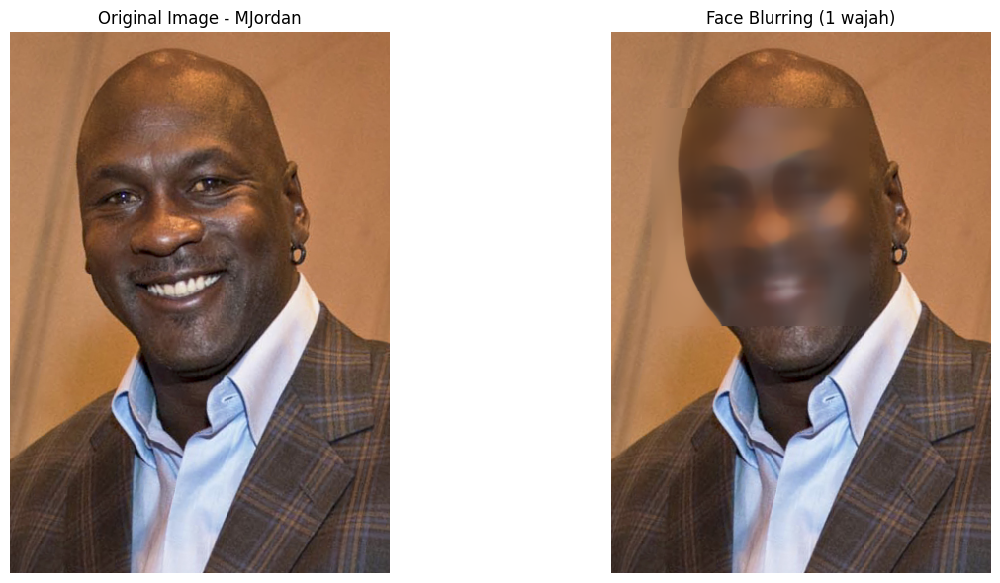

Jumlah wajah terdeteksi: 1


In [16]:
# Mencari gambar MJordan di folder facedet
BLUR_IMAGE_PATH = cari_file(
    'MJordan.jpg',
    alternatif=('mjordan.jpeg', 'mjordan.png', 'michael-jordan.jpg'),
    subdir='facedet'
)

# Membaca gambar
blur_img = cv2.imread(str(BLUR_IMAGE_PATH))

if blur_img is None:
    raise ValueError('Gambar MJordan gagal dibaca.')

# Mengubah gambar menjadi grayscale
blur_gray = cv2.cvtColor(blur_img, cv2.COLOR_BGR2GRAY)

# Memuat Haar Cascade
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_alt.xml'
)

# Mendeteksi wajah
blur_faces = face_cascade.detectMultiScale(
    blur_gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(25, 25)
)

# Menyalin gambar asli
blur_result = blur_img.copy()

# Melakukan blurring pada wajah
for (x, y, w, h) in blur_faces:
    roi = blur_result[y:y+h, x:x+w]

    ukuran_kernel = min(31, min(w, h))
    if ukuran_kernel % 2 == 0:
        ukuran_kernel -= 1

    ukuran_kernel = max(3, ukuran_kernel)

    roi_blur = cv2.medianBlur(roi, ukuran_kernel)
    blur_result[y:y+h, x:x+w] = roi_blur

# Menampilkan hasil
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(cv2.cvtColor(blur_img, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original Image - MJordan')

axes[1].imshow(cv2.cvtColor(blur_result, cv2.COLOR_BGR2RGB))
axes[1].set_title(f'Face Blurring ({len(blur_faces)} wajah)')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Jumlah wajah terdeteksi:', len(blur_faces))

## 14. Mengolah gambar KTM masing-masing

### 14a–14b. Menampilkan KTM dan foto pada KTM

Simpan foto KTM milik sendiri di folder pribadi Google Drive. Atur `KTM_PATH`. Setelah gambar ditampilkan, isi koordinat crop foto dalam format `(x, y, lebar, tinggi)` berdasarkan ukuran gambar. Koordinat dapat dilihat dari ukuran gambar yang dicetak.

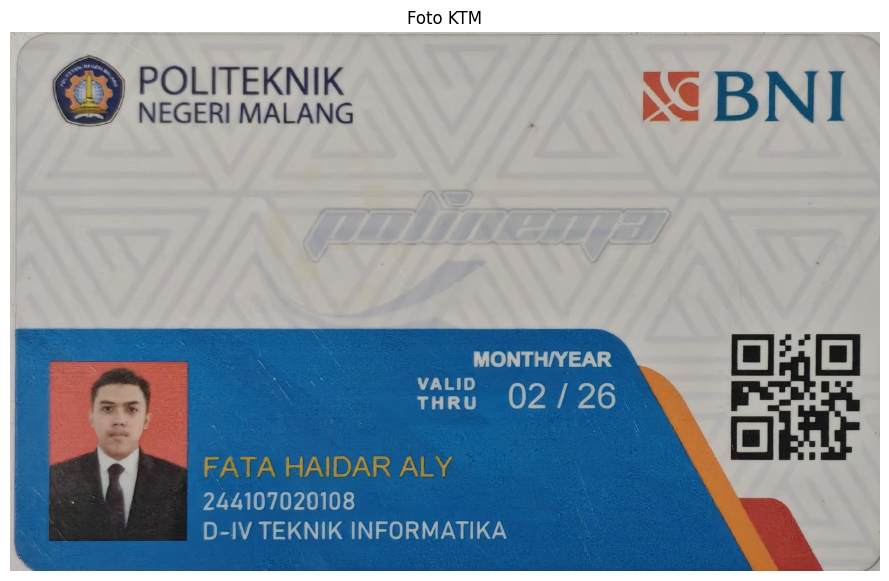

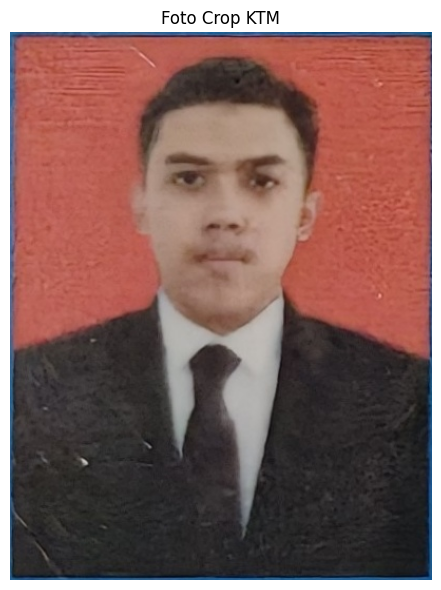

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca foto KTM
KTM_PATH = '/content/drive/MyDrive/PCVK/KTM lama.jpg'
ktm_img = cv2.imread(KTM_PATH)

if ktm_img is None:
    raise ValueError('Foto KTM tidak ditemukan!')

# 1. Menampilkan KTM utuh
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(ktm_img, cv2.COLOR_BGR2RGB))
plt.title('Foto KTM')
plt.axis('off')
plt.show()

# 2. Crop foto mahasiswa dari KTM
# Format: x, y, lebar, tinggi
x, y, w, h = 110, 940, 400, 520

foto_crop = ktm_img[y:y+h, x:x+w].copy()

# 3. Menghilangkan background menggunakan GrabCut
mask = np.zeros(foto_crop.shape[:2], np.uint8)

bg_model = np.zeros((1, 65), np.float64)
fg_model = np.zeros((1, 65), np.float64)

rect = (3, 3, w-6, h-6)

cv2.grabCut(
    foto_crop,
    mask,
    rect,
    bg_model,
    fg_model,
    5,
    cv2.GC_INIT_WITH_RECT
)

# Membuat mask orang
mask_person = np.where(
    (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
    1, 0
).astype(np.uint8)

# 4. Membuat background warna merah
background_merah = np.zeros_like(foto_crop)
background_merah[:] = (0, 0, 255)

# Menggabungkan foto orang dengan background merah
mask_3 = mask_person[:, :, np.newaxis]

hasil_crop = (
    foto_crop * mask_3 +
    background_merah * (1 - mask_3)
).astype(np.uint8)

# 5. Menampilkan hasil crop
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(foto_crop, cv2.COLOR_BGR2RGB))
plt.title('Foto Crop KTM')
plt.axis('off')

plt.tight_layout()
plt.show()

### 14c. Deteksi objek KTM di antara barang lain dengan Feature Matching

Gunakan foto KTM sebagai **template** dan foto yang berisi KTM bersama barang lain sebagai **scene**. ORB mengekstrak keypoint/deskriptor, Brute-Force Matcher memasangkan deskriptor, dan Homography RANSAC memperkirakan posisi KTM pada scene.

Template: KTM_template.png
Scene: ktm_bersama_barang.png
Keypoint template: 1402
Keypoint scene: 1183
Jumlah matches: 500
Jumlah inlier: 437
KTM berhasil dideteksi!


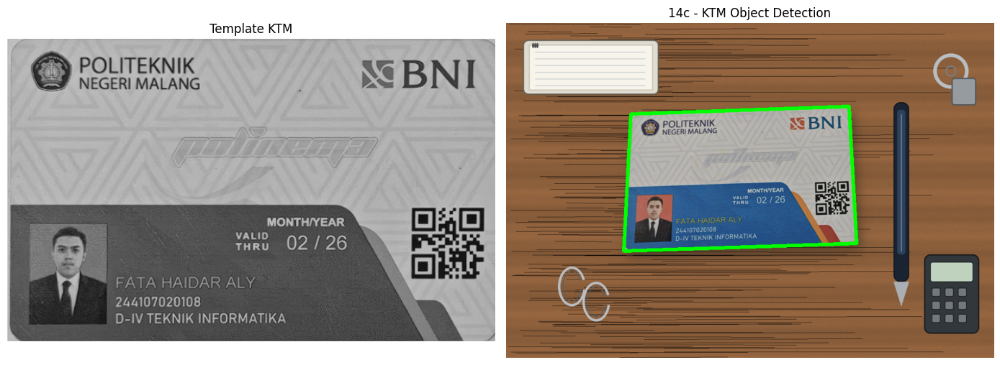

In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Lokasi folder PCVK
BASE_DIR = Path('/content/drive/MyDrive/PCVK')

# Mencari file tanpa mempermasalahkan huruf besar/kecil
def cari_file_pcvk(nama):
    for p in BASE_DIR.rglob('*'):
        if p.is_file() and p.name.lower() == nama.lower():
            return p
    raise FileNotFoundError(f'File {nama} tidak ditemukan di PCVK')

# 1. Membaca gambar template dan scene
template_path = cari_file_pcvk('KTM_template.png')
scene_path = cari_file_pcvk('ktm_bersama_barang.png')

template = cv2.imread(str(template_path), cv2.IMREAD_GRAYSCALE)
scene = cv2.imread(str(scene_path), cv2.IMREAD_GRAYSCALE)

if template is None or scene is None:
    raise ValueError('Gambar gagal dibaca.')

print('Template:', template_path.name)
print('Scene:', scene_path.name)

# 2. Membuat SIFT detector
sift = cv2.SIFT_create(nfeatures=5000)

kp1, des1 = sift.detectAndCompute(template, None)
kp2, des2 = sift.detectAndCompute(scene, None)

print('Keypoint template:', len(kp1))
print('Keypoint scene:', len(kp2))

# 3. Feature Matching
bf = cv2.BFMatcher(cv2.NORM_L2)

matches = bf.knnMatch(des1, des2, k=2)

good = [
    m for pair in matches
    if len(pair) == 2
    for m, n in [pair]
    if m.distance < 0.75 * n.distance
]

print('Jumlah matches:', len(good))

# 4. Deteksi objek KTM
if len(good) >= 4:

    src_pts = np.float32(
        [kp1[m.queryIdx].pt for m in good]
    ).reshape(-1, 1, 2)

    dst_pts = np.float32(
        [kp2[m.trainIdx].pt for m in good]
    ).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(
        src_pts, dst_pts, cv2.RANSAC, 5.0
    )

    if H is not None:

        inliers = int(mask.sum())
        print('Jumlah inlier:', inliers)

        h, w = template.shape

        corners = np.float32([
            [0, 0],
            [w-1, 0],
            [w-1, h-1],
            [0, h-1]
        ]).reshape(-1, 1, 2)

        dst = cv2.perspectiveTransform(corners, H)

        hasil = cv2.imread(str(scene_path))

        cv2.polylines(
            hasil,
            [np.int32(dst)],
            True,
            (0, 255, 0),
            5
        )

        print('KTM berhasil dideteksi!')

        # 5. Menampilkan hasil
        plt.figure(figsize=(14, 7))

        plt.subplot(1, 2, 1)
        plt.imshow(template, cmap='gray')
        plt.title('Template KTM')
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB))
        plt.title('14c - KTM Object Detection')
        plt.axis('off')

        plt.tight_layout()
        plt.show()

    else:
        print('Homography gagal ditemukan.')

else:
    print('Feature matching tidak mencukupi.')

# D3. Tugas Pengayaan — Pengenalan Karakter KTM dengan CNN

Tujuan: mengenali karakter pada KTM menggunakan CNN. Siapkan dataset hasil crop karakter terlebih dahulu. Struktur folder yang digunakan:

```text
dataset/
├── training/
│   ├── 0/
│   ├── 1/
│   ├── ...
│   ├── 9/
│   ├── A/
│   └── ...
└── testing/
    ├── ktm_1/
    │   ├── char_01.png
    │   ├── char_02.png
    │   └── ...
    └── ktm_2/
        └── ...
```

Setiap subfolder `training` berisi banyak contoh gambar untuk satu karakter. Data testing berisi potongan karakter dari setiap KTM, diurutkan sesuai urutan karakter yang akan dibaca.

## D3.1 Persiapan data training

Kode ini mengikuti alur modul: membaca setiap kelas karakter, mengubah gambar menjadi grayscale berukuran 100×100, mengacak data, lalu menyimpan fitur dan label dalam file pickle.

In [38]:
import random
import pickle
from tqdm.notebook import tqdm

# GANTI jika folder dataset berada di lokasi lain.
DATASET_DIR = Path('/content/drive/MyDrive/PCVK/dataset')
TRAIN_DIR = DATASET_DIR / 'training'
TEST_DIR = DATASET_DIR / 'testing'

WIDTH, HEIGHT = 100, 100

if not TRAIN_DIR.exists():
    raise FileNotFoundError(
        f'Folder training tidak ditemukan: {TRAIN_DIR}. '
        'Buat subfolder per karakter dan isi dengan gambar hasil crop.'
    )

kelas = sorted([
    p.name for p in TRAIN_DIR.iterdir()
    if p.is_dir() and not p.name.startswith('.')
])
training_data = []

for char_name in kelas:
    folder_kelas = TRAIN_DIR / char_name
    for file_gambar in tqdm(list(folder_kelas.iterdir()), desc=char_name):
        if not file_gambar.is_file():
            continue
        try:
            img_array = cv2.imread(str(file_gambar), cv2.IMREAD_GRAYSCALE)
            if img_array is None:
                continue
            new_array = cv2.resize(img_array, (WIDTH, HEIGHT))
            training_data.append([new_array, kelas.index(char_name)])
        except Exception as e:
            print('Lewati file:', file_gambar, '|', e)

random.shuffle(training_data)
if not training_data:
    raise ValueError('Dataset training kosong. Isi folder kelas dengan gambar karakter.')

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X, dtype=np.uint8).reshape(-1, WIDTH, HEIGHT, 1)
Y = np.array(Y, dtype=np.int64)

with open(DATASET_DIR / 'X.pickle', 'wb') as f:
    pickle.dump(X, f)
with open(DATASET_DIR / 'Y.pickle', 'wb') as f:
    pickle.dump(Y, f)
with open(DATASET_DIR / 'kelas.pickle', 'wb') as f:
    pickle.dump(kelas, f)

print('Jumlah data :', len(training_data))
print('Jumlah kelas:', len(kelas), kelas)
print('Shape X:', X.shape, '| Shape Y:', Y.shape)

0: 0it [00:00, ?it/s]

1: 0it [00:00, ?it/s]

2: 0it [00:00, ?it/s]

3: 0it [00:00, ?it/s]

4:   0%|          | 0/72 [00:00<?, ?it/s]

5: 0it [00:00, ?it/s]

... (27 outputs left out)

X: 0it [00:00, ?it/s]

Y: 0it [00:00, ?it/s]

Z: 0it [00:00, ?it/s]

Jumlah data : 448
Jumlah kelas: 36 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Shape X: (448, 100, 100, 1) | Shape Y: (448,)


## D3.2 Training CNN

Arsitektur CNN mengikuti modul: ZeroPadding2D, Conv2D, MaxPooling2D, Flatten, Dense, dan output Softmax. Model disimpan sebagai `anpr.keras`.

Epoch 1/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 520ms/step - accuracy: 0.1592 - loss: 2.2845 - val_accuracy: 0.3222 - val_loss: 1.8016
Epoch 2/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 747ms/step - accuracy: 0.3436 - loss: 1.6846 - val_accuracy: 0.3556 - val_loss: 1.5310
Epoch 3/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 476ms/step - accuracy: 0.3324 - loss: 1.5613 - val_accuracy: 0.3667 - val_loss: 1.4308
Epoch 4/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 585ms/step - accuracy: 0.4078 - loss: 1.4471 - val_accuracy: 0.3556 - val_loss: 1.5226
Epoch 5/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 481ms/step - accuracy: 0.4553 - loss: 1.3768 - val_accuracy: 0.5556 - val_loss: 1.2797
Epoch 6/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 567ms/step - accuracy: 0.5475 - loss: 1.2349 - val_accuracy: 0.4778 - val_loss: 1.1733
Epoch 7/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 690ms/step - accuracy: 0.6006 - loss: 1.1125 - val_accuracy: 0.5111 - val_loss: 1.0411
Epoch 8/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 484ms/step - accuracy: 0.7235 - loss: 0.9005 - val_accuracy

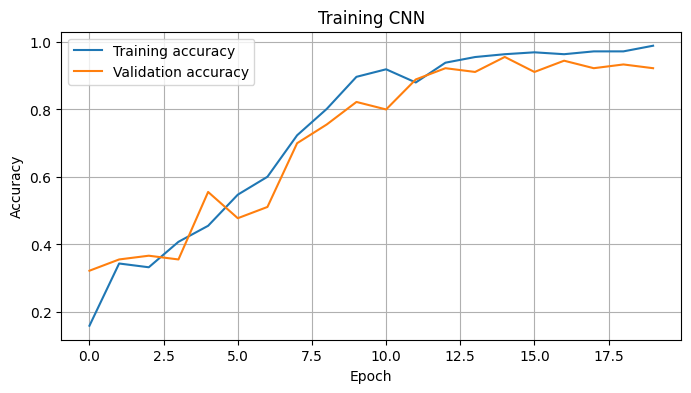

In [39]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

with open(DATASET_DIR / 'X.pickle', 'rb') as f:
    X = pickle.load(f)
with open(DATASET_DIR / 'Y.pickle', 'rb') as f:
    Y = pickle.load(f)

X = X.astype('float32') / 255.0
Y_cat = to_categorical(Y)
jumlah_kelas = Y_cat.shape[1]

inputs = Input(shape=(WIDTH, HEIGHT, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

riwayat = model.fit(
    X, Y_cat, epochs=20, verbose=1, validation_split=0.2, shuffle=True
)

MODEL_PATH = DATASET_DIR / 'anpr.keras'
model.save(MODEL_PATH)

print('Akurasi training :', riwayat.history['accuracy'][-1])
print('Akurasi validasi :', riwayat.history['val_accuracy'][-1])
print('Model tersimpan  :', MODEL_PATH)

plt.figure(figsize=(8, 4))
plt.plot(riwayat.history['accuracy'], label='Training accuracy')
plt.plot(riwayat.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training CNN')
plt.legend()
plt.grid(True)
plt.show()

## D3.3 Testing pengenalan karakter KTM

Setiap folder di dalam `testing` mewakili satu KTM. Gambar karakter di dalam folder harus sudah diurutkan sesuai posisi baca. Model memprediksi karakter satu per satu dan menggabungkan hasilnya menjadi teks.

In [41]:
model = tf.keras.models.load_model(MODEL_PATH)
with open(DATASET_DIR / 'kelas.pickle', 'rb') as f:
    kelas = pickle.load(f)

if not TEST_DIR.exists():
    print(f'Folder testing belum tersedia: {TEST_DIR}')
else:
    for folder_ktm in sorted(p for p in TEST_DIR.iterdir() if p.is_dir()):
        hasil_teks = ''
        file_karakter = sorted(
            p for p in folder_ktm.iterdir()
            if p.is_file() and p.suffix.lower() in ekstensi_gambar
        )

        for file_karakter in file_karakter:
            img_array = cv2.imread(str(file_karakter), cv2.IMREAD_GRAYSCALE)
            if img_array is None:
                continue
            new_array = cv2.resize(img_array, (WIDTH, HEIGHT))
            input_array = new_array.reshape(1, WIDTH, HEIGHT, 1).astype('float32') / 255.0
            prediction = model.predict(input_array, verbose=0)
            indeks = int(np.argmax(prediction[0]))
            hasil_teks += kelas[indeks]

        print(f'Folder KTM: {folder_ktm.name} | Hasil prediksi: {hasil_teks}')

Folder KTM: KTMku | Hasil prediksi: 


## Kesimpulan praktikum

Setelah semua sel berhasil dijalankan, simpan notebook beserta hasil visualisasi untuk dokumentasi praktikum. Pastikan:
- Nomor 2 menghasilkan perbandingan enam metode template matching.
- Nomor 3 menandai beberapa kemunculan objek Bahrain.
- Nomor 4–7 menampilkan hasil edge, corner, grid, dan contour detection.
- Nomor 8–13 menampilkan hasil face/eye/smile detection, tracking, dan blurring.
- Nomor 14 memakai foto KTM sendiri dan foto scene yang benar-benar memuat KTM tersebut.
- D3 memakai dataset karakter training/testing yang disiapkan sendiri.

**Catatan pelaporan:** jangan menuliskan angka akurasi atau jumlah deteksi sebelum notebook dijalankan. Gunakan nilai yang benar-benar muncul dari hasil eksekusi Anda.